In [2]:
from chembl_webresource_client.new_client import new_client
import pandas as pd

target_client = new_client.target
my_genes = ['CXCR4', 'TGFB1', 'ITGB1', 'MYH11', 'SELE']

target_mapping = []

for gene in my_genes:
    # Query using the gene symbol component
    res = target_client.filter(target_synonym__icontains=gene)
    for record in res:
        # Keep human single proteins to ensure accurate data matching
        if record.get('organism') == 'Homo sapiens' and record.get('target_type') == 'SINGLE PROTEIN':
            target_mapping.append({
                'Gene_Symbol': gene,
                'ChEMBL_ID': record.get('target_chembl_id'),
                'Description': record.get('pref_name'),
                'Target_Type': record.get('target_type')
            })

df_targets = pd.DataFrame(target_mapping).drop_duplicates(subset=['ChEMBL_ID'])
print(df_targets)


   Gene_Symbol      ChEMBL_ID  \
0        CXCR4     CHEMBL2107   
1        TGFB1  CHEMBL1795178   
2        ITGB1     CHEMBL1905   
3         SELE     CHEMBL1785   
4         SELE     CHEMBL3595   
5         SELE     CHEMBL2009   
6         SELE     CHEMBL4016   
7         SELE     CHEMBL2239   
8         SELE     CHEMBL4183   
9         SELE     CHEMBL3890   
10        SELE     CHEMBL2403   
11        SELE     CHEMBL3923   
12        SELE     CHEMBL3190   
13        SELE     CHEMBL3161   
14        SELE     CHEMBL5378   
15        SELE     CHEMBL4746   
16        SELE     CHEMBL4574   
17        SELE     CHEMBL5650   
18        SELE     CHEMBL6190   
19        SELE  CHEMBL1628469   
20        SELE  CHEMBL3596077   
21        SELE  CHEMBL4295729   
22        SELE  CHEMBL4295741   
23        SELE  CHEMBL4523145   
24        SELE  CHEMBL4523505   
25        SELE  CHEMBL5723576   
26        SELE  CHEMBL5725088   
27        SELE  CHEMBL6066434   
28        SELE  CHEMBL6067320   
29        

In [5]:
df_targets

,Gene_Symbol,ChEMBL_ID,Description,Target_Type
0,CXCR4,CHEMBL2107,C-X-C chemokine receptor type 4,SINGLE PROTEIN
1,TGFB1,CHEMBL1795178,Transforming growth factor beta-1 proprotein,SINGLE PROTEIN
2,ITGB1,CHEMBL1905,Integrin beta-1,SINGLE PROTEIN
3,SELE,CHEMBL1785,Endothelin receptor type B,SINGLE PROTEIN
4,SELE,CHEMBL3595,Glutamate receptor 3,SINGLE PROTEIN
5,SELE,CHEMBL2009,Glutamate receptor 1,SINGLE PROTEIN
6,SELE,CHEMBL4016,Glutamate receptor 2,SINGLE PROTEIN
7,SELE,CHEMBL2239,Carbohydrate sulfotransferase 4,SINGLE PROTEIN
8,SELE,CHEMBL4183,P-selectin glycoprotein ligand 1,SINGLE PROTEIN
9,SELE,CHEMBL3890,E-selectin,SINGLE PROTEIN


In [6]:
from chembl_webresource_client.new_client import new_client
import pandas as pd

# 1. Hardcode your verified, cleaned Human ChEMBL IDs
cleaned_targets = {
    'CXCR4': 'CHEMBL2107',
    'TGFB1': 'CHEMBL1795178',
    'ITGB1': 'CHEMBL1905',
    'MYH11': 'CHEMBL3425',
    'SELE':  'CHEMBL3890'
}

activity_client = new_client.activity
molecule_client = new_client.molecule

ml_data = []
approved_drugs = []

# 2. Extract Data for Each Target
for gene, chembl_id in cleaned_targets.items():
    print(f"Processing {gene} ({chembl_id})...")
    
    # --- PIPELINE B: Get all molecules with IC50 bioactivity for ML ---
    activities = activity_client.filter(target_chembl_id=chembl_id, standard_type="IC50")
    
    for act in list(activities):
        smiles = act.get('molecule_structures', {}).get('canonical_smiles') if act.get('molecule_structures') else None
        if smiles and act.get('standard_value'):
            ml_data.append({
                'Gene_Symbol': gene,
                'Target_ChEMBL_ID': chembl_id,
                'Molecule_ChEMBL_ID': act.get('molecule_chembl_id'),
                'Canonical_SMILES': smiles,
                'IC50_Value': float(act.get('standard_value')),
                'Unit': act.get('standard_units')
            })
            
    # --- PIPELINE A: Get approved drugs actively targeting these proteins ---
    # Max_phase = 4 means fully FDA approved
    drugs = molecule_client.filter(target_chembl_id=chembl_id, max_phase=4)
    for drug in list(drugs):
        approved_drugs.append({
            'Target_Gene': gene,
            'Drug_Name': drug.get('pref_name'),
            'Drug_ChEMBL_ID': drug.get('molecule_chembl_id'),
            'Molecule_Type': drug.get('molecule_type'),
            'Structure_SMILES': drug.get('molecule_structures', {}).get('canonical_smiles') if drug.get('molecule_structures') else None
        })

# 3. Save Pipeline A (Drug Repurposing)
df_drugs = pd.DataFrame(approved_drugs).drop_duplicates(subset=['Drug_ChEMBL_ID'])
df_drugs.to_csv('approved_drugs_repurposing.csv', index=False)
print(f"\nSaved {len(df_drugs)} approved drugs to 'approved_drugs_repurposing.csv'")

# 4. Save Pipeline B (Machine Learning Dataset)
df_ml = pd.DataFrame(ml_data)
df_ml.to_csv('ml_bioactivity_dataset.csv', index=False)
print(f"Saved {len(df_ml)} bioactivity rows to 'ml_bioactivity_dataset.csv'")


Processing CXCR4 (CHEMBL2107)...
Processing TGFB1 (CHEMBL1795178)...
Processing ITGB1 (CHEMBL1905)...
Processing MYH11 (CHEMBL3425)...
Processing SELE (CHEMBL3890)...

Saved 4225 approved drugs to 'approved_drugs_repurposing.csv'
Saved 0 bioactivity rows to 'ml_bioactivity_dataset.csv'


In [6]:
# DOWNLOAD-GofzQ-8L8sLxvGzC9LzLZMDXY1WeUSYsUm_W0OtcGXE_eq_.csv

import pandas as pd
gof  = pd.read_csv('DOWNLOAD-GofzQ-8L8sLxvGzC9LzLZMDXY1WeUSYsUm_W0OtcGXE_eq_.csv', sep=';')
gof.columns

Index(['Compound ChEMBL ID', 'Name', 'Synonyms', 'Type', 'Max Phase',
       'Molecular Weight', 'Targets', 'Bioactivities', 'AlogP',
       'Polar Surface Area', 'HBA', 'HBD', '#RO5 Violations',
       '#Rotatable Bonds', 'Passes Ro3', 'QED Weighted', 'Aromatic Rings',
       'Structure Type', 'Inorganic Flag', 'Heavy Atoms', 'Np Likeness Score',
       'Molecular Formula', 'Smiles', 'Inchi Key', 'Inchi', 'Withdrawn Flag',
       'Orphan', 'Records Key', 'Records Name'],
      dtype='str')

In [8]:
gof.shape

(274, 29)

In [10]:
gof.isnull().sum() 

Compound ChEMBL ID      0
Name                  187
Synonyms              201
Type                    0
Max Phase             204
Molecular Weight        0
Targets                 9
Bioactivities           9
AlogP                   9
Polar Surface Area      9
HBA                     9
HBD                     9
#RO5 Violations         9
#Rotatable Bonds        9
Passes Ro3              9
QED Weighted            9
Aromatic Rings          9
Structure Type          0
Inorganic Flag          0
Heavy Atoms             9
Np Likeness Score       9
Molecular Formula       0
Smiles                  0
Inchi Key               0
Inchi                   0
Withdrawn Flag          0
Orphan                  0
Records Key             4
Records Name            4
dtype: int64

In [9]:
gof.sample(10)

,Compound ChEMBL ID,Name,Synonyms,Type,Max Phase,Molecular Weight,Targets,Bioactivities,AlogP,Polar Surface Area,...,Heavy Atoms,Np Likeness Score,Molecular Formula,Smiles,Inchi Key,Inchi,Withdrawn Flag,Orphan,Records Key,Records Name
195,CHEMBL1257,ENFLURANE,ALYRANE|ANESTHETIC COMPOUND NO. 347|COMPOUND 3...,Small molecule,4.0,184.49,10.0,69.0,2.35,9.23,...,10.0,-0.10,C3H2ClF5O,FC(F)OC(F)(F)C(F)Cl,JPGQOUSTVILISH-UHFFFAOYSA-N,"InChI=1S/C3H2ClF5O/c4-1(5)3(8,9)10-2(6)7/h1-2H",False,0,"['Enflurane', 'Enflurane', 'Enflurane', 'SID50...","['Enflurane', '2-Chloro-1-difluoromethoxy-1,1,..."
202,CHEMBL21079,NaN,NaN,Small molecule,NaN,397.44,6.0,6.0,4.08,93.85,...,30.0,-1.58,C23H19N5O2,Cc1ccc(NC(=O)c2ccccc2)cc1Nc1nccc(-c2ccc[n+]([O...,GVVKCRDZWNNGEY-UHFFFAOYSA-N,InChI=1S/C23H19N5O2/c1-16-9-10-19(25-22(29)17-...,False,-1,['13'],['N-{4-Methyl-3-[4-(1-oxy-pyridin-3-yl)-pyrimi...
46,CHEMBL21107,NaN,NaN,Small molecule,NaN,328.38,1.0,3.0,3.93,23.55,...,23.0,-0.91,C17H23F3N2O,CCC(=O)N(c1ccc(C(F)(F)F)cc1)C1CCCC1N(C)C,JPHNQGBDWVDAIV-UHFFFAOYSA-N,InChI=1S/C17H23F3N2O/c1-4-16(23)22(15-7-5-6-14...,False,-1,['63'],['N-(2-Dimethylamino-cyclopentyl)-N-(4-trifluo...
21,CHEMBL21067,NaN,NaN,Small molecule,NaN,454.60,1.0,1.0,3.67,95.94,...,29.0,-0.98,C19H22N2O5S3,COc1ccc(S(=O)(=O)N(Cc2sc3scc(C)c3c2C)[C@H](C)C...,NFRVWANPGCGVPV-CYBMUJFWSA-N,InChI=1S/C19H22N2O5S3/c1-11-10-27-19-17(11)12(...,False,-1,['25'],"['(R)-2-[(3,4-Dimethyl-thieno[2,3-b]thiophen-2..."
8,CHEMBL11047,NaN,NaN,Small molecule,NaN,271.32,2.0,2.0,0.93,81.99,...,20.0,-0.08,C15H17N3O2,CC(=O)NC(Cc1ccccc1)C(=O)NC/C=C/C#N,FJVOYZLNEMKBDO-AATRIKPKSA-N,InChI=1S/C15H17N3O2/c1-12(19)18-14(11-13-7-3-2...,False,-1,['1d'],['2-Acetylamino-N-(3-cyano-allyl)-3-phenyl-pro...
13,CHEMBL21073,NaN,NaN,Small molecule,NaN,664.53,1.0,2.0,3.96,152.73,...,42.0,-0.78,C28H30BrN3O9S,COc1ccc(S(=O)(=O)N(Cc2ccc3c(c2)OCO3)[C@H](CCCN...,LCVNKFOOCIFLMG-XMMPIXPASA-N,InChI=1S/C28H30BrN3O9S/c1-38-21-9-11-22(12-10-...,False,-1,"['11', 'in table 1']","['{(R)-4-[Benzo[1,3]dioxol-5-ylmethyl-(4-metho..."
219,CHEMBL210247,NaN,NaN,Protein,NaN,557.65,3.0,4.0,1.32,167.85,...,41.0,-0.30,C31H35N5O5,NC(=O)[C@H](Cc1ccccc1)NC(=O)[C@H](NC(=O)[C@@H]...,CLTFAZZUUWSIAO-YIPNQBBMSA-N,InChI=1S/C31H35N5O5/c32-24(18-21-13-15-23(37)1...,False,-1,['6'],['Tyr-Pro-D-Phg-Phe-NH2']
258,CHEMBL419213,LISINOPRIL,ACEMIN|CARACE|LISINOPRIL|LISINOPRIL COMPONENT ...,Small molecule,4.0,441.53,11.0,26.0,1.24,132.96,...,29.0,0.20,C21H35N3O7,NCCCC[C@H](N[C@@H](CCc1ccccc1)C(=O)O)C(=O)N1CC...,CZRQXSDBMCMPNJ-ZUIPZQNBSA-N,InChI=1S/C21H31N3O5.2H2O/c22-13-5-4-9-16(19(25...,False,0,"['Lisinopril', 'SID11113057', 'LISINOPRIL', 'L...","['Lisinopril', 'SID11113057', 'LISINOPRIL', 'L..."
153,CHEMBL1200901,HALOFANTRINE HYDROCHLORIDE,HALFAN|HALOFANTRINE HCL|HALOFANTRINE HYDROCHLO...,Small molecule,4.0,536.89,28.0,64.0,8.64,23.47,...,33.0,-0.73,C26H31Cl3F3NO,CCCCN(CCCC)CCC(O)c1cc2c(Cl)cc(Cl)cc2c2cc(C(F)(...,WANGFTDWOFGECH-UHFFFAOYSA-N,InChI=1S/C26H30Cl2F3NO.ClH/c1-3-5-10-32(11-6-4...,False,0,"['SID56463552', 'SID170465140', 'SID11112745',...","['SID56463552', 'SID170465140', 'SID11112745',..."
207,CHEMBL132107,NaN,NaN,Small molecule,NaN,297.43,3.0,4.0,4.50,37.81,...,21.0,-1.73,C17H19N3S,CC(C)Cc1nc(NCc2ccccc2)c2sccc2n1,VIKCKGGIIODBFN-UHFFFAOYSA-N,InChI=1S/C17H19N3S/c1-12(2)10-15-19-14-8-9-21-...,False,-1,['13'],"['Benzyl-(2-isobutyl-thieno[3,2-d]pyrimidin-4-..."


In [13]:
import pandas as pd
import ast

df = pd.read_csv("DOWNLOAD-GofzQ-8L8sLxvGzC9LzLZMDXY1WeUSYsUm_W0OtcGXE_eq_.csv", sep=";")

def safe_parse(x):
    try:
        # If it's already a number, just return it
        if isinstance(x, (int, float)):
            return x
        # If it's a string that looks like a number
        if str(x).replace(".", "", 1).isdigit():
            return float(x)
        # Otherwise try to parse as list/dict
        return ast.literal_eval(str(x))
    except:
        return None

df["Bioactivities_parsed"] = df["Bioactivities"].apply(safe_parse)

# Extract IC50 values
def get_ic50(bioacts):
    if isinstance(bioacts, list):  # JSON-like list of dicts
        for act in bioacts:
            if isinstance(act, dict) and act.get("activity_type") == "IC50":
                return act.get("value")
    elif isinstance(bioacts, (int, float)):  # direct numeric value
        return bioacts
    return None

df["IC50"] = df["Bioactivities_parsed"].apply(get_ic50)

# Filter potent compounds
potent = df[df["IC50"].notnull() & (df["IC50"] < 1000)]
print(potent[["Compound ChEMBL ID", "Name", "IC50"]])


    Compound ChEMBL ID                         Name   IC50
0          CHEMBL21075                          NaN    1.0
1         CHEMBL121076                          NaN    5.0
2          CHEMBL12187                          NaN    3.0
3           CHEMBL1127             7-HYDROXYTACRINE    4.0
4         CHEMBL521807                          NaN    2.0
..                 ...                          ...    ...
268         CHEMBL1202  CIPROFLOXACIN HYDROCHLORIDE  174.0
269         CHEMBL1087                  MEPIVACAINE  413.0
270         CHEMBL1170      TESTOSTERONE PROPIONATE  226.0
272         CHEMBL1072                   BUMETANIDE  391.0
273         CHEMBL1187              PHOSPHORIC ACID   30.0

[259 rows x 3 columns]


In [14]:
df.sort_values("IC50")

,Compound ChEMBL ID,Name,Synonyms,Type,Max Phase,Molecular Weight,Targets,Bioactivities,AlogP,Polar Surface Area,...,Molecular Formula,Smiles,Inchi Key,Inchi,Withdrawn Flag,Orphan,Records Key,Records Name,Bioactivities_parsed,IC50
0,CHEMBL21075,NaN,NaN,Small molecule,NaN,683.08,1.0,1.0,6.41,86.79,...,C18H13Cl8N3O4S2,O=S(=O)(NS(=O)(=O)N1CCc2c(Cl)c(Cl)c(Cl)c(Cl)c2...,DDJXKQZPZJZTCI-UHFFFAOYSA-N,InChI=1S/C18H13Cl8N3O4S2/c19-11-7-1-3-28(5-9(7...,False,-1,['38'],"['5,6,7,8-tetrachloro-N-[(5,6,7,8-tetrachloro-...",1.0,1.0
104,CHEMBL12075,NaN,NaN,Small molecule,NaN,324.47,1.0,1.0,3.02,69.64,...,C18H32N2O3,CN(C)CCCCCCC/C=C(\NC(=O)C1CC1(C)C)C(=O)O,JNPTWAFWEMCYHF-PTNGSMBKSA-N,InChI=1S/C18H32N2O3/c1-18(2)13-14(18)16(21)19-...,False,-1,['222'],"['10-Dimethylamino-2-[(2,2-dimethyl-cyclopropa...",1.0,1.0
102,CHEMBL333442,LESCOL,NaN,Small molecule,NaN,433.46,1.0,1.0,4.63,82.69,...,C24H25FNNaO4,CC(C)n1c(/C=C/[C@@H](O)C[C@@H](O)CC(=O)[O-])c(...,ZGGHKIMDNBDHJB-NRFPMOEYSA-M,InChI=1S/C24H26FNO4.Na/c1-15(2)26-21-6-4-3-5-2...,False,-1,['EOS100776'],['Fluvastatin sodium (Lescol)'],1.0,1.0
209,CHEMBL21927,NaN,NaN,Protein,NaN,528.56,1.0,1.0,-0.07,208.15,...,C26H32N4O8,C[C@H](NC(=O)[C@H](CCC(=O)O)NC(=O)[C@@H](N)Cc1...,RKYSBVDKYXOCCT-ZEWNOJEFSA-N,InChI=1S/C26H32N4O8/c1-15(23(34)30-21(26(37)38...,False,-1,['20'],['YEAF'],1.0,1.0
210,CHEMBL216074,NaN,NaN,Protein,NaN,1347.66,1.0,1.0,NaN,NaN,...,C63H98N18O13S,CSCC[C@H](NC(=O)[C@@H](CC(C)C)NC(=O)CNC(=O)[C@...,ADNPLDHMAVUMIW-SPLPJBQPSA-N,InChI=1S/C63H98N18O13S/c1-37(2)33-45(57(89)74-...,False,-1,['407'],['Substance P analogue'],1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,CHEMBL11079,NaN,NaN,Small molecule,NaN,226.29,NaN,NaN,0.90,23.55,...,C12H19FN2O,CC(=O)N(C)CC#CCN1CCC[C@@H]1CF,ZTQOQOORKLHVHC-GFCCVEGCSA-N,InChI=1S/C12H19FN2O/c1-11(16)14(2)7-3-4-8-15-9...,False,-1,NaN,NaN,NaN,NaN
199,CHEMBL1200516,GONADORELIN HYDROCHLORIDE,"AY-24,031|AY-24031|FACTREL|GONADORELIN HCL|GON...",Protein,4.0,1218.77,NaN,NaN,NaN,NaN,...,C55H76ClN17O13,CC(C)C[C@H](NC(=O)CNC(=O)[C@H](Cc1ccc(O)cc1)NC...,UPRWQSQENCASAD-HBBGHHHDSA-N,InChI=1S/C55H75N17O13.ClH/c1-29(2)19-38(49(80)...,False,0,"['GONADORELIN HYDROCHLORIDE', 'GONADORELIN HYD...","['GONADORELIN HYDROCHLORIDE', 'GONADORELIN HYD...",NaN,NaN
234,CHEMBL1200463,OXAPROZIN POTASSIUM,DAYPRO ALTA|OXAPROZIN POTASSIUM,Small molecule,4.0,331.41,NaN,NaN,4.03,63.33,...,C18H14KNO3,O=C([O-])CCc1nc(-c2ccccc2)c(-c2ccccc2)o1.[K+],QTAQWNSMRSLSCG-UHFFFAOYSA-M,InChI=1S/C18H15NO3.K/c20-16(21)12-11-15-19-17(...,False,0,"['OXAPROZIN POTASSIUM', 'OXAPROZIN POTASSIUM']","['OXAPROZIN POTASSIUM', 'OXAPROZIN POTASSIUM']",NaN,NaN
246,CHEMBL3989824,THIOTHIXENE HYDROCHLORIDE,"CP-12,252-1|CP-122521|NAVANE|THIOTHIXENE DIHYD...",Small molecule,4.0,552.59,NaN,NaN,3.47,43.86,...,C23H35Cl2N3O4S2,CN1CCN(CC/C=C2/c3ccccc3Sc3ccc(S(=O)(=O)N(C)C)c...,MEUAAEMCZUPORO-LRSHZYOCSA-N,"InChI=1S/C23H29N3O2S2.2ClH.2H2O/c1-24(2)30(27,...",False,0,"['THIOTHIXENE HYDROCHLORIDE', 'THIOTHIXENE HYD...","['THIOTHIXENE HYDROCHLORIDE', 'THIOTHIXENE HYD...",NaN,NaN


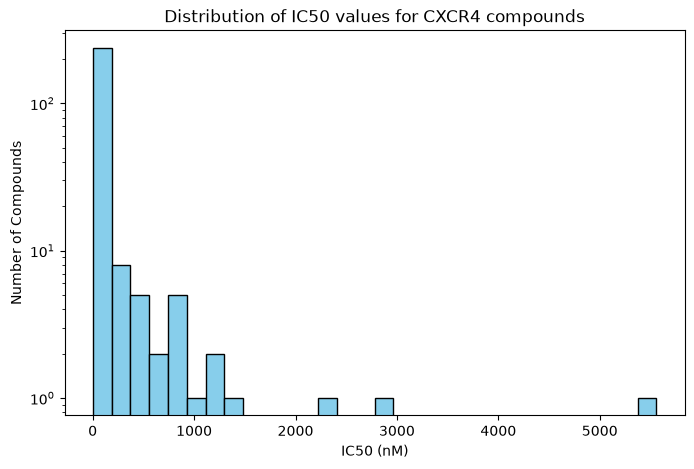

In [16]:
import matplotlib.pyplot as plt

# Drop missing values
ic50_values = df["IC50"].dropna()

plt.figure(figsize=(8,5))
plt.hist(ic50_values, bins=30, color="skyblue", edgecolor="black")
plt.xlabel("IC50 (nM)")
plt.ylabel("Number of Compounds")
plt.title("Distribution of IC50 values for CXCR4 compounds")
plt.yscale("log")  # optional: log scale if values vary widely
plt.show()


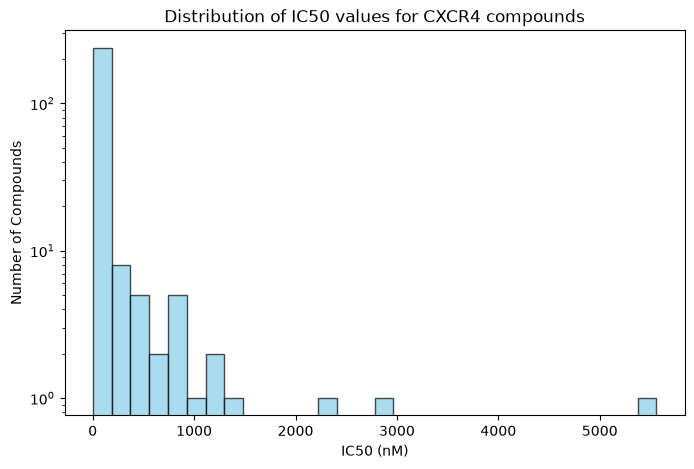

In [19]:
import matplotlib.pyplot as plt

# Histogram of IC50 values
ic50_values = df["IC50"].dropna()

plt.figure(figsize=(8,5))
plt.hist(ic50_values, bins=30, color="skyblue", edgecolor="black", alpha=0.7)
plt.xlabel("IC50 (nM)")
plt.ylabel("Number of Compounds")
plt.title("Distribution of IC50 values for CXCR4 compounds")
plt.yscale("log")  # log scale helps if values vary widely
plt.show()

# Apply drug-likeness filters
# Lipinski: HBA <= 10, HBD <= 5, MW <= 500, AlogP <= 5
lipinski = df[
    (df["HBA"] <= 10) &
    (df["HBD"] <= 5) &
    (df["Molecular Weight"] <= 500) &
    (df["AlogP"] <= 5)
]

# QED Weighted (quantitative estimate of drug-likeness) > 0.6 is often considered good
druglike = lipinski[lipinski["QED Weighted"] > 0.6]

# Potent + druglike compounds
potent_druglike = druglike[druglike["IC50"].notnull() & (druglike["IC50"] < 1000)]

# Show top 10 potent & druglike
top10_druglike = potent_druglike.sort_values("IC50").head(10)
# print(top10_druglike[["Compound ChEMBL ID", "Name", "IC50", "Molecular Weight", "AlogP", "QED Weighted"]])


In [55]:
top10_druglike

,Compound ChEMBL ID,Name,Synonyms,Type,Max Phase,Molecular Weight,Targets,Bioactivities,AlogP,Polar Surface Area,...,Heavy Atoms,Np Likeness Score,Molecular Formula,Smiles,Inchi Key,Inchi,Withdrawn Flag,Orphan,Records Key,Records Name
287,CHEMBL1395978,NaN,NaN,Small molecule,NaN,263.24,10.0,12.0,3.23,38.33,...,19.0,-1.75,C14H11F2NO2,COc1cccc(NC(=O)c2c(F)cccc2F)c1,UKERRYQGHATEEO-UHFFFAOYSA-N,InChI=1S/C14H11F2NO2/c1-19-10-5-2-4-9(8-10)17-...,False,-1,['SID56436722'],['SID56436722']
191,CHEMBL1393178,NaN,NaN,Small molecule,NaN,326.40,4.0,4.0,4.07,50.80,...,24.0,-0.98,C19H22N2O3,COc1ccc(C2CCCN2C(=O)Nc2ccccc2)cc1OC,PTGHEFVLYRIBGC-UHFFFAOYSA-N,InChI=1S/C19H22N2O3/c1-23-17-11-10-14(13-18(17...,False,-1,['SID14738704'],['SID14738704']
256,CHEMBL1379517,NaN,NaN,Small molecule,NaN,317.35,8.0,9.0,1.08,88.83,...,23.0,-2.33,C15H19N5O3,CCOC(=O)N1CCC(NC(=O)c2cnn3cccnc23)CC1,ZAUJYJRFTUQFRX-UHFFFAOYSA-N,InChI=1S/C15H19N5O3/c1-2-23-15(22)19-8-4-11(5-...,False,-1,['SID4262085'],['SID4262085']
160,CHEMBL1099178,NaN,NaN,Small molecule,NaN,342.94,3.0,4.0,3.43,26.71,...,22.0,-0.49,C17H27ClN2OS,CN1CCN(C[C@@H](c2csc(Cl)c2)C2(O)CCCCC2)CC1,KHYNNQYNYMSTIB-HNNXBMFYSA-N,InChI=1S/C17H27ClN2OS/c1-19-7-9-20(10-8-19)12-...,False,-1,['(-)-R-21'],['(-)-R-1-(1-(5-chlorothiophen-3-yl)-2-(4-meth...
248,CHEMBL1399178,NaN,NaN,Small molecule,NaN,259.31,7.0,8.0,2.57,51.47,...,19.0,-1.26,C15H17NO3,COc1ccccc1CCNC(=O)c1ccc(C)o1,WOZRGHXIKYOCAX-UHFFFAOYSA-N,InChI=1S/C15H17NO3/c1-11-7-8-14(19-11)15(17)16...,False,-1,['SID4259302'],['SID4259302']
20,CHEMBL1491178,NaN,NaN,Small molecule,NaN,277.32,2.0,2.0,2.16,66.84,...,20.0,-1.00,C15H19NO4,CCCOc1ccc(C(=O)N2CCCC2C(=O)O)cc1,MRVWHOSSKWDZJG-UHFFFAOYSA-N,InChI=1S/C15H19NO4/c1-2-10-20-12-7-5-11(6-8-12...,False,-1,['SID845716'],['SID845716']
131,CHEMBL1395179,NaN,NaN,Small molecule,NaN,354.19,5.0,5.0,3.34,64.63,...,23.0,-1.70,C16H13Cl2NO4,COc1ccccc1C(=O)NC(=O)COc1cc(Cl)ccc1Cl,ACUITZYLCZXALQ-UHFFFAOYSA-N,InChI=1S/C16H13Cl2NO4/c1-22-13-5-3-2-4-11(13)1...,False,-1,['SID56322082'],['SID56322082']
55,CHEMBL1715178,NaN,NaN,Small molecule,NaN,344.85,4.0,4.0,2.27,61.02,...,24.0,-1.00,C18H21ClN4O,O=C(Cc1ccc(Cl)cc1)N1CCC2(CC1)NCCc1[nH]cnc12,VLVBPVOYGVQDLM-UHFFFAOYSA-N,InChI=1S/C18H21ClN4O/c19-14-3-1-13(2-4-14)11-1...,False,-1,['SID49825018'],['SID49825018']
1,CHEMBL1379518,NaN,NaN,Small molecule,NaN,368.42,3.0,3.0,1.63,118.54,...,25.0,-2.80,C15H20N4O5S,Cc1cc(NC(=O)C2CCCN(S(=O)(=O)c3c(C)noc3C)C2)no1,JMLRAYQWUARGFY-UHFFFAOYSA-N,InChI=1S/C15H20N4O5S/c1-9-7-13(18-23-9)16-15(2...,False,-1,['SID7966542'],['SID7966542']
266,CHEMBL1395170,NaN,NaN,Small molecule,NaN,354.47,6.0,7.0,1.61,75.71,...,24.0,-1.81,C17H26N2O4S,Cc1ccc(S(=O)(=O)NCCC(=O)N2CC(C)OC(C)C2)cc1C,UPHZDGFRGZWVME-UHFFFAOYSA-N,InChI=1S/C17H26N2O4S/c1-12-5-6-16(9-13(12)2)24...,False,-1,['SID56315916'],['SID56315916']


In [33]:
top10_druglike.columns

Index(['Compound ChEMBL ID', 'Name', 'Synonyms', 'Type', 'Max Phase',
       'Molecular Weight', 'Targets', 'Bioactivities', 'AlogP',
       'Polar Surface Area', 'HBA', 'HBD', '#RO5 Violations',
       '#Rotatable Bonds', 'Passes Ro3', 'QED Weighted', 'Aromatic Rings',
       'Structure Type', 'Inorganic Flag', 'Heavy Atoms', 'Np Likeness Score',
       'Molecular Formula', 'Smiles', 'Inchi Key', 'Inchi', 'Withdrawn Flag',
       'Orphan', 'Records Key', 'Records Name', 'Bioactivities_parsed',
       'IC50'],
      dtype='str')

In [34]:
df2.columns

Index(['Compound ChEMBL ID', 'Name', 'Synonyms', 'Type', 'Max Phase',
       'Molecular Weight', 'Targets', 'Bioactivities', 'AlogP',
       'Polar Surface Area', 'HBA', 'HBD', '#RO5 Violations',
       '#Rotatable Bonds', 'Passes Ro3', 'QED Weighted', 'Aromatic Rings',
       'Structure Type', 'Inorganic Flag', 'Heavy Atoms', 'Np Likeness Score',
       'Molecular Formula', 'Smiles', 'Inchi Key', 'Inchi', 'Withdrawn Flag',
       'Orphan', 'Records Key', 'Records Name'],
      dtype='str')

In [27]:
df2 = pd.read_csv('CHEMBL1795178.csv', sep = ';')
df2.head()

,Compound ChEMBL ID,Name,Synonyms,Type,Max Phase,Molecular Weight,Targets,Bioactivities,AlogP,Polar Surface Area,...,Heavy Atoms,Np Likeness Score,Molecular Formula,Smiles,Inchi Key,Inchi,Withdrawn Flag,Orphan,Records Key,Records Name
0,CHEMBL1495171,NaN,NaN,Small molecule,NaN,399.45,18.0,25.0,5.04,77.25,...,30.0,-1.46,C24H21N3O3,Cc1cccc(C)c1OCC(=O)Nc1cccc(-c2nnc(-c3ccccc3)o2)c1,HIKDTXVJPVLUEL-UHFFFAOYSA-N,InChI=1S/C24H21N3O3/c1-16-8-6-9-17(2)22(16)29-...,False,-1,['SID859774'],['SID859774']
1,CHEMBL1379518,NaN,NaN,Small molecule,NaN,368.42,3.0,3.0,1.63,118.54,...,25.0,-2.80,C15H20N4O5S,Cc1cc(NC(=O)C2CCCN(S(=O)(=O)c3c(C)noc3C)C2)no1,JMLRAYQWUARGFY-UHFFFAOYSA-N,InChI=1S/C15H20N4O5S/c1-9-7-13(18-23-9)16-15(2...,False,-1,['SID7966542'],['SID7966542']
2,CHEMBL1079178,NaN,NaN,Small molecule,NaN,338.29,2.0,2.0,1.08,113.29,...,24.0,1.42,C16H15FO7,COc1cc(O)c2c(c1)/C=C/C[C@@H](O)[C@@H](O)C(=O)/...,IMOBDMOEKOBTBM-CONFRVSISA-N,InChI=1S/C16H15FO7/c1-23-9-5-8-3-2-4-11(18)15(...,False,-1,['23'],"['(3Z,6R,7R,9E)-4-fluoro-6,7,14-trihydroxy-12-..."
3,CHEMBL1195158,NaN,NaN,Small molecule,NaN,355.22,NaN,NaN,2.73,98.57,...,23.0,-0.05,C16H16Cl2N2O3,NCCOc1ccc(C(=O)c2ccc(O)c(CN)c2)c(Cl)c1Cl,FMKFBWLCAOCJFS-UHFFFAOYSA-N,InChI=1S/C16H16Cl2N2O3/c17-14-11(2-4-13(15(14)...,False,-1,NaN,NaN
4,CHEMBL1498178,NaN,NaN,Small molecule,NaN,224.31,16.0,24.0,2.77,41.99,...,14.0,-3.25,C9H8N2OS2,Cc1cnc(NC(=O)c2cccs2)s1,JDJXKXFGRRAOOV-UHFFFAOYSA-N,InChI=1S/C9H8N2OS2/c1-6-5-10-9(14-6)11-8(12)7-...,False,-1,['SID49673742'],['SID49673742']


In [37]:
top10_druglike = df2[
    (df2["HBA"] <= 10) &
    (df2["HBD"] <= 5) &
    (df2["Molecular Weight"] <= 500) &
    (df2["AlogP"] <= 5) &
    (df2["QED Weighted"] > 0.6)
].sort_values("QED Weighted", ascending=False).head(10)


top10_druglike[["Compound ChEMBL ID", "Name", "QED Weighted", "Max Phase"]]
#top10_druglike

,Compound ChEMBL ID,Name,QED Weighted,Max Phase
287,CHEMBL1395978,NaN,0.92,NaN
191,CHEMBL1393178,NaN,0.92,NaN
256,CHEMBL1379517,NaN,0.91,NaN
160,CHEMBL1099178,NaN,0.91,NaN
248,CHEMBL1399178,NaN,0.90,NaN
20,CHEMBL1491178,NaN,0.90,NaN
131,CHEMBL1395179,NaN,0.89,NaN
55,CHEMBL1715178,NaN,0.88,NaN
58,CHEMBL1579518,NaN,0.87,NaN
143,CHEMBL553993,NaN,0.87,NaN


In [43]:
# druglike = druglike[
#     (druglike["HBA"] <= 10) &
#     (druglike["HBD"] <= 5) &
#     (druglike["Molecular Weight"] <= 500) &
#     (druglike["AlogP"] <= 5)
# ]
df2.isnull().sum()

Compound ChEMBL ID      0
Name                  294
Synonyms              295
Type                    1
Max Phase             295
Molecular Weight        1
Targets                43
Bioactivities          43
AlogP                   7
Polar Surface Area      7
HBA                     7
HBD                     7
#RO5 Violations         7
#Rotatable Bonds        7
Passes Ro3              7
QED Weighted            7
Aromatic Rings          7
Structure Type          0
Inorganic Flag          0
Heavy Atoms             7
Np Likeness Score       7
Molecular Formula       1
Smiles                  2
Inchi Key               2
Inchi                   2
Withdrawn Flag          0
Orphan                  0
Records Key            42
Records Name           42
dtype: int64

In [44]:
# Filter only rows with QED values
druglike = df2[df2["QED Weighted"].notnull()]

# Apply Lipinski filters
druglike = druglike[
    (druglike["HBA"] <= 10) &
    (druglike["HBD"] <= 5) &
    (druglike["Molecular Weight"] <= 500) &
    (druglike["AlogP"] <= 5)
]

# Sort by QED score
top10_druglike = druglike.sort_values("QED Weighted", ascending=False).head(10)

print(top10_druglike[["Compound ChEMBL ID", "QED Weighted", "Max Phase"]])


    Compound ChEMBL ID  QED Weighted  Max Phase
287      CHEMBL1395978          0.92        NaN
191      CHEMBL1393178          0.92        NaN
256      CHEMBL1379517          0.91        NaN
160      CHEMBL1099178          0.91        NaN
248      CHEMBL1399178          0.90        NaN
20       CHEMBL1491178          0.90        NaN
131      CHEMBL1395179          0.89        NaN
55       CHEMBL1715178          0.88        NaN
1        CHEMBL1379518          0.87        NaN
266      CHEMBL1395170          0.87        NaN


In [59]:
import pandas as pd

# Load your ChEMBL1905 dataset, skipping any malformed rows
df = pd.read_csv("CHEMBL1905.csv", sep=";", on_bad_lines='skip')

In [61]:
# Quick look at the successfully loaded data
print(f"Successfully loaded {df.shape[0]} rows and {df.shape[1]} columns.")
df.head()

Successfully loaded 270 rows and 29 columns.


,Compound ChEMBL ID,Name,Synonyms,Type,Max Phase,Molecular Weight,Targets,Bioactivities,AlogP,Polar Surface Area,...,Heavy Atoms,Np Likeness Score,Molecular Formula,Smiles,Inchi Key,Inchi,Withdrawn Flag,Orphan,Records Key,Records Name
0,CHEMBL1052,NORMEPERIDINE,NaN,Small molecule,NaN,233.31,2.0,2.0,1.87,38.33,...,17.0,-0.20,C14H19NO2,CCOC(=O)C1(c2ccccc2)CCNCC1,QKHMFBKXTNQCTM-UHFFFAOYSA-N,InChI=1S/C14H19NO2/c1-2-17-13(16)14(8-10-15-11...,False,-1,"['12', 'Normeperidine']",['4-Phenyl-piperidine-4-carboxylic acid ethyl ...
1,CHEMBL10953,NaN,NaN,Small molecule,NaN,449.53,4.0,5.0,3.73,92.70,...,32.0,-0.39,C25H23NO5S,COc1ccc(-c2ccc(S(=O)(=O)NC(CC#CCc3ccccc3)C(=O)...,PMHIYNQSFXKIMZ-UHFFFAOYSA-N,InChI=1S/C25H23NO5S/c1-31-22-15-11-20(12-16-22...,False,-1,"['21', '47']",[2-(4'-Methoxy-biphenyl-4-sulfonylamino)-6-phe...
2,CHEMBL109405,NaN,NaN,Small molecule,NaN,225.29,14.0,22.0,3.50,16.38,...,17.0,0.11,C15H15NO,C1=C(c2cc3ccccc3o2)C2CCN1CC2,AYQKIBOBFAZBCX-UHFFFAOYSA-N,InChI=1S/C15H15NO/c1-2-4-14-12(3-1)9-15(17-14)...,False,-1,"['1', '31', '675', '3h']",['3-Benzofuran-2-yl-1-aza-bicyclo[2.2.2]oct-2-...
3,CHEMBL11059,NaN,NaN,Small molecule,NaN,266.34,NaN,NaN,0.50,49.85,...,19.0,-0.43,C14H22N2O3,CC(=O)OC[C@H]1CCCN1CC#CCN(C)C(C)=O,POOXXSNKRQDMHV-CQSZACIVSA-N,InChI=1S/C14H22N2O3/c1-12(17)15(3)8-4-5-9-16-1...,False,-1,NaN,NaN
4,CHEMBL71905,NaN,NaN,Small molecule,NaN,202.04,7.0,8.0,2.45,54.70,...,12.0,-0.95,C7H5Cl2N3,Nc1nc2cc(Cl)c(Cl)cc2[nH]1,HAADRTMPUSJNOI-UHFFFAOYSA-N,InChI=1S/C7H5Cl2N3/c8-3-1-5-6(2-4(3)9)12-7(10)...,False,-1,"['14', '3', '12']","['5,6-Dichloro-1H-benzoimidazol-2-ylamine', '5..."


In [63]:
df.columns

Index(['Compound ChEMBL ID', 'Name', 'Synonyms', 'Type', 'Max Phase',
       'Molecular Weight', 'Targets', 'Bioactivities', 'AlogP',
       'Polar Surface Area', 'HBA', 'HBD', '#RO5 Violations',
       '#Rotatable Bonds', 'Passes Ro3', 'QED Weighted', 'Aromatic Rings',
       'Structure Type', 'Inorganic Flag', 'Heavy Atoms', 'Np Likeness Score',
       'Molecular Formula', 'Smiles', 'Inchi Key', 'Inchi', 'Withdrawn Flag',
       'Orphan', 'Records Key', 'Records Name'],
      dtype='str')

In [64]:
!pip install chembl_webresource_client rdkit pandas scikit-learn


In [65]:
import pandas as pd
from chembl_webresource_client.new_client import new_client
from rdkit import Chem
from rdkit.Chem import AllChem
import numpy as np

# =====================================================================
# STEP 1: Fetch Bioactivity Data from ChEMBL
# =====================================================================
print("Fetching data from ChEMBL... (This may take a minute)")
activity = new_client.activity
# CHEMBL220 is the unique ID for Human Acetylcholinesterase
res = activity.filter(target_chembl_id='CHEMBL220').filter(standard_type="IC50")
df = pd.DataFrame.from_dict(res)

# =====================================================================
# STEP 2: Filter and Clean Data
# =====================================================================
# Drop rows missing crucial values
df = df.dropna(subset=['standard_value', 'canonical_smiles'])
# Ensure numerical values and keep only standard 'nM' units
df['standard_value'] = pd.to_numeric(df['standard_value'])
df = df[df['standard_units'] == 'nM']

# Drop duplicates, keeping the lowest IC50 (most potent) for duplicates
df = df.sort_values(by='standard_value').drop_duplicates(subset=['canonical_smiles'], keep='first')

# Convert IC50 to pIC50 (-log10 of IC50 in Molar) for better ML scaling
# 1 nM = 1e-9 M -> pIC50 = 9 - log10(IC50_nM)
df['pIC50'] = 9 - np.log10(df['standard_value'])

print(f"Cleaned dataset contains {len(df)} unique molecules.")

# =====================================================================
# STEP 3: Molecular Featurization (Convert SMILES to ML Features)
# =====================================================================
def smiles_to_fp(smiles, radius=2, n_bits=2048):
    """Converts a SMILES string into a 2048-bit Morgan Fingerprint vector."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    # Generate bit vector
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    # Convert to a numpy array of 0s and 1s
    return np.array(fp)

print("Generating Morgan Fingerprints...")
features = []
labels = []

for idx, row in df.iterrows():
    fp = smiles_to_fp(row['canonical_smiles'])
    if fp is not None:
        features.append(fp)
        labels.append(row['pIC50'])

X = np.array(features)  # Your ML Feature Matrix (shape: N x 2048)
y = np.array(labels)    # Your ML Target Array (shape: N)

print(f"Dataset ready for ML! X shape: {X.shape}, y shape: {y.shape}")


Fetching data from ChEMBL... (This may take a minute)


d:\PriceTracker\ng\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[0

Cleaned dataset contains 7102 unique molecules.
Generating Morgan Fingerprints...


[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerator
[01:54:02] DEPRECATION WARNING: please use MorganGenerat

Dataset ready for ML! X shape: (7102, 2048), y shape: (7102,)
